In [22]:
import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import Perceptron
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix

from tensorflow.keras.models import Sequential
#this lets me build neural network layer by layer in keras
from tensorflow.keras.layers import Dense #dense makes the final prediction
from tensorflow.keras.layers import Conv2D #conv2d extract features
from tensorflow.keras.layers import Flatten #flatter reshape kore

from tensorflow.keras.layers import MaxPool2D #maxpooling kore- size reduce
from tensorflow.keras.layers import Dropout 
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

from tensorflow.keras.utils import to_categorical #converts numerical into labels into one hot encoding format

In [4]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("abenjelloun/breast-mri-tumor-classification-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'breast-mri-tumor-classification-dataset' dataset.
Path to dataset files: /kaggle/input/breast-mri-tumor-classification-dataset


In [11]:
import os

dataset_path = "/kaggle/input/breast-mri-tumor-classification-dataset"

# check inside folders
for dir_name,subdir,filenames in os.walk(dataset_path):
    for filename in filenames:
        print(os.path.join(dir_name,filename))


/kaggle/input/breast-mri-tumor-classification-dataset/breast_mri_dataset_original_shape/val/Benign/BREASTDX-01-0036_727.jpg
/kaggle/input/breast-mri-tumor-classification-dataset/breast_mri_dataset_original_shape/val/Benign/BREASTDX-01-0007_367.jpg
/kaggle/input/breast-mri-tumor-classification-dataset/breast_mri_dataset_original_shape/val/Benign/BREASTDX-01-0066_1951.jpg
/kaggle/input/breast-mri-tumor-classification-dataset/breast_mri_dataset_original_shape/val/Benign/BREASTDX-01-0004_1782.jpg
/kaggle/input/breast-mri-tumor-classification-dataset/breast_mri_dataset_original_shape/val/Benign/BREASTDX-01-0001_1990.jpg
/kaggle/input/breast-mri-tumor-classification-dataset/breast_mri_dataset_original_shape/val/Benign/BREASTDX-01-0035_60.jpg
/kaggle/input/breast-mri-tumor-classification-dataset/breast_mri_dataset_original_shape/val/Benign/BREASTDX-01-0028_2091.jpg
/kaggle/input/breast-mri-tumor-classification-dataset/breast_mri_dataset_original_shape/val/Benign/BREASTDX-01-0012_404.jpg
/kagg

In [13]:
import os
import matplotlib.pyplot as plt
from PIL import Image

# Base path (after kagglehub download)
BASE_PATH = "/kaggle/input/breast-mri-tumor-classification-dataset/breast_mri_dataset_original_shape"

splits = ['train', 'val', 'test']
classes = ['Benign', 'Malignant']

# Count images per split per class
print(f"{'Split':<10} {'Benign':<12} {'Malignant':<12} {'Total'}")
print("-" * 44)
for split in splits:
    counts = {}
    for cls in classes:
        folder = os.path.join(BASE_PATH, split, cls)
        counts[cls] = len(os.listdir(folder))
    total = sum(counts.values())
    print(f"{split:<10} {counts['Benign']:<12} {counts['Malignant']:<12} {total}")

Split      Benign       Malignant    Total
--------------------------------------------
train      8413         8413         16826
val        1797         1797         3594
test       1802         1802         3604


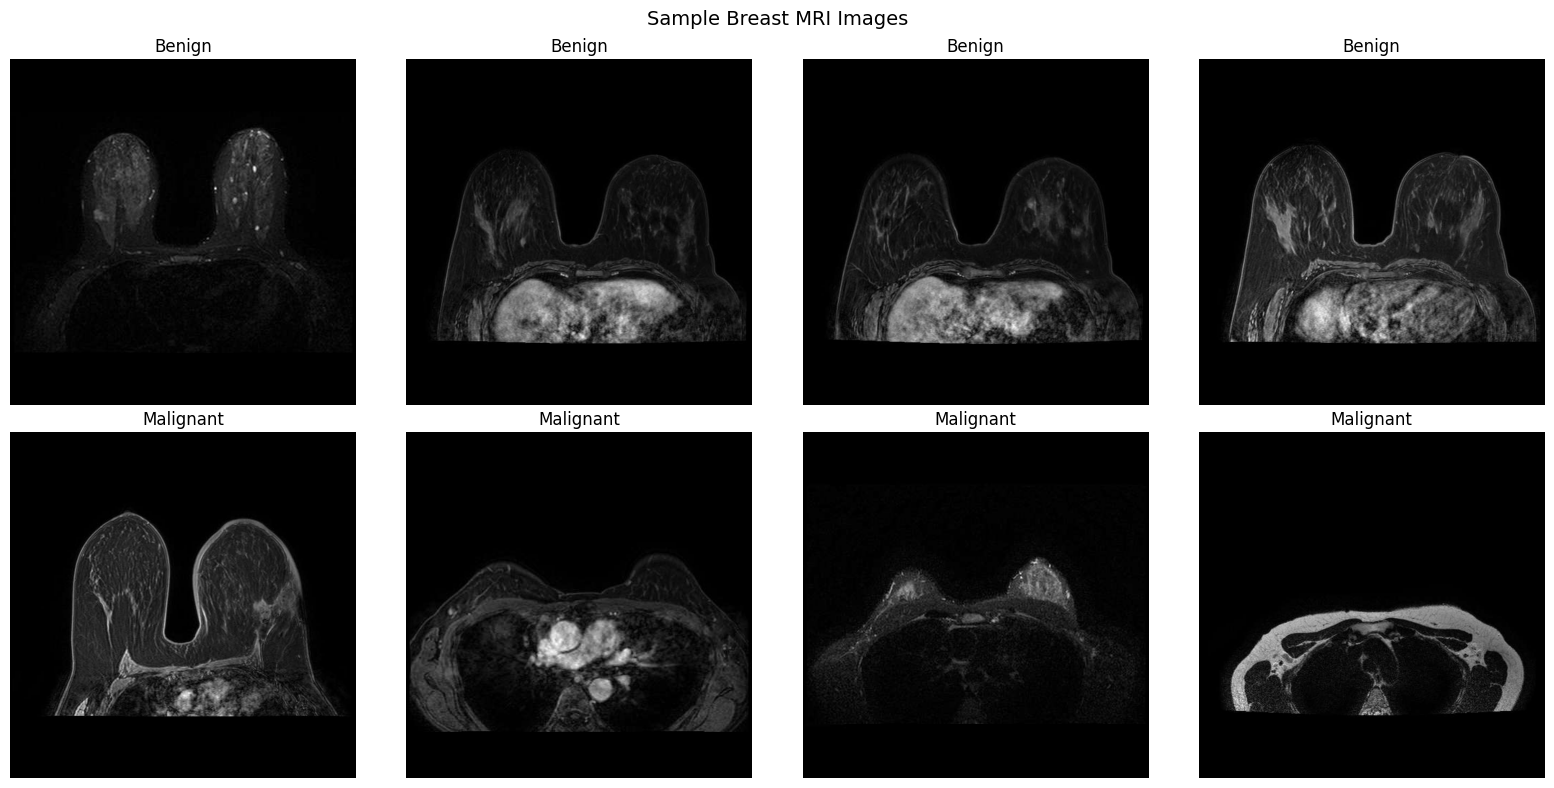

In [14]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
fig.suptitle("Sample Breast MRI Images", fontsize=14)

for row, cls in enumerate(classes):
    folder = os.path.join(BASE_PATH, 'train', cls)
    sample_imgs = os.listdir(folder)[:4]
    for col, fname in enumerate(sample_imgs):
        img = Image.open(os.path.join(folder, fname)).convert('RGB')
        axes[row][col].imshow(img, cmap='gray')
        axes[row][col].set_title(f"{cls}")
        axes[row][col].axis('off')

plt.tight_layout()
plt.show()

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

IMG_SIZE = (224,224)
BATCH_SIZE = 32

#train with augmentation

train_datagen = ImageDataGenerator(
   rescale = 1./255, #pixel value ke 0-255 ke 0.0 to 1.0 te convert
   rotation_range=10,
   zoom_range=0.1,
   width_shift_range=0.05,
   height_shift_range=0.05,
   horizontal_flip=True
)

test_datagen = ImageDataGenerator(rescale=1./255)

train_gen = train_datagen.flow_from_directory(
    os.path.join(BASE_PATH, 'train'),
    target_size = IMG_SIZE,
    batch_size = BATCH_SIZE,
    class_mode = 'binary',
    color_mode = 'rgb'
)

val_gen = test_datagen.flow_from_directory(
    os.path.join(BASE_PATH, 'val'),
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    color_mode='rgb',
    shuffle=False
)

test_gen = test_datagen.flow_from_directory(
    os.path.join(BASE_PATH, 'test'),
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    color_mode='rgb',
    shuffle=False
)
print("Class indices:", train_gen.class_indices)

Found 16826 images belonging to 2 classes.
Found 3594 images belonging to 2 classes.
Found 3604 images belonging to 2 classes.
Class indices: {'Benign': 0, 'Malignant': 1}


In [20]:
#building my cnn for medical image

CNN = Sequential([
    Conv2D(32,(3,3),activation='relu',input_shape=(224,224,3)),
    MaxPool2D(2,2),
    Conv2D(64,(3,3),activation='relu'),
    MaxPool2D(2,2),

    Conv2D(128,(3,3),activation='relu'),
    MaxPool2D(2,2),

    Flatten(),
    Dense(512,activation='relu'),
    Dropout(0.5),
    Dense(1,activation='sigmoid')
])
CNN.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │    44,302,848 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 44,396,609 (169.36 MB)

 Trainable params: 44,396,609 (169.36 MB)

 Non-trainable params: 0 (0.00 B)

In [21]:
CNN.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy',tf.keras.metrics.AUC(name='auc')] #auc for medical
)

In [ ]:
callbacks = [
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
    ModelCheckpoint('best_breast_mri_model.h5', monitor='val_auc', save_best_only=True, mode='max'),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, verbose=1)
]


history= CNN.fit(
    train_gen,
    epochs=30,
    validation_data=val_gen,
    callbacks=callbacks
)

Epoch 1/30
145/526 ━━━━━━━━━━━━━━━━━━━━ 4:23 691ms/step - accuracy: 0.5356 - auc: 0.5452 - loss: 0.7147